<a href="https://colab.research.google.com/github/Asinjoji/Assessment3/blob/main/Assessment_3_Asin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.Data Understanding and Exploratory Analysis

In [51]:
import pandas as pd

In [52]:
df=pd.read_csv('/content/drive/MyDrive/DSA/Dataset/bank_marketing_assessment_dataset.csv')
df

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,30,blue-collar,single,primary,638.0,no,no,cellular,oct,5,0,7,86357,no
596,68,blue-collar,single,tertiary,-70.0,no,yes,unknown,may,11,2,1,49674,yes
597,33,admin,single,secondary,7.0,no,yes,cellular,jul,5,0,3,12000,no
598,28,admin,single,secondary,1831.0,no,no,cellular,jul,4,1,3,23176,no


In [53]:
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [54]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_age            600 non-null    int64  
 1   job                     600 non-null    object 
 2   marital_status          600 non-null    object 
 3   education               585 non-null    object 
 4   account_balance         588 non-null    float64
 5   housing_loan            600 non-null    object 
 6   personal_loan           600 non-null    object 
 7   contact_type            591 non-null    object 
 8   contact_month           600 non-null    object 
 9   campaign_contacts       600 non-null    int64  
 10  previous_contacts       600 non-null    int64  
 11  engagement_score        600 non-null    int64  
 12  annual_income_estimate  600 non-null    int64  
 13  subscribed              600 non-null    object 
dtypes: float64(1), int64(5), object(8)
memory 

In [56]:
df.describe()

,customer_age,account_balance,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate
count,600.000000,588.000000,600.000000,600.000000,600.000000,600.0000
mean,38.208333,1535.037415,5.566667,1.015000,4.451667,31805.3650
std,15.387426,2366.916896,2.020485,1.582914,2.938603,17264.0821
min,18.000000,-5418.000000,3.000000,0.000000,1.000000,12000.0000
25%,26.000000,-24.750000,4.000000,0.000000,1.000000,16112.5000
50%,34.000000,1589.500000,5.000000,0.000000,4.000000,29156.0000
75%,49.000000,3042.750000,7.000000,2.000000,7.000000,43444.0000
max,75.000000,9365.000000,13.000000,8.000000,10.000000,108930.0000


In [57]:
df.isnull().sum()

,0
customer_age,0
job,0
marital_status,0
education,15
account_balance,12
housing_loan,0
personal_loan,0
contact_type,9
contact_month,0
campaign_contacts,0


In [58]:
df.duplicated().sum()

np.int64(0)

In [59]:
df.shape

(600, 14)

In [60]:
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
df['subscribed'].value_counts()

,count
subscribed,
no,426
yes,174


In [63]:
df['subscribed'].value_counts(normalize=True) * 100

,proportion
subscribed,
no,71.0
yes,29.0


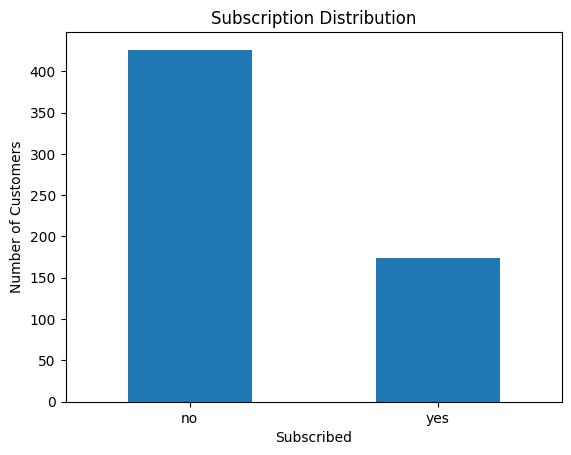

In [64]:
df['subscribed'].value_counts().plot(kind='bar')
plt.title("Subscription Distribution")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

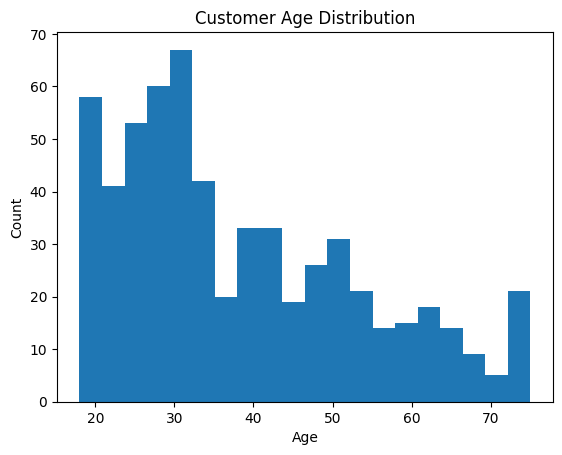

In [65]:
plt.hist(df['customer_age'], bins=20)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

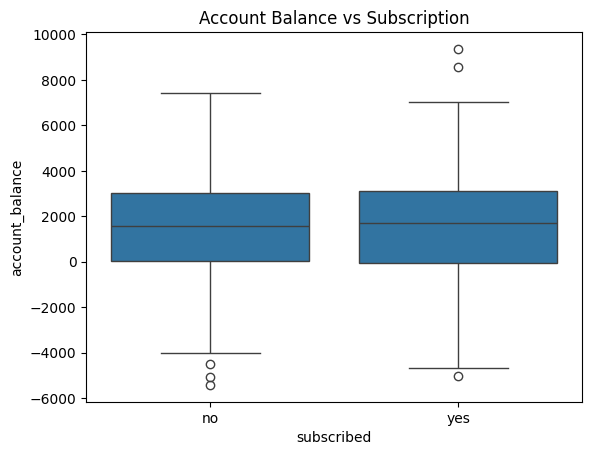

In [66]:
sns.boxplot(x='subscribed', y='account_balance', data=df)
plt.title("Account Balance vs Subscription")
plt.show()

2.Data Preparation and Feature Engineering

In [67]:
X = df.drop('subscribed', axis=1)
y = df['subscribed']

In [68]:
print(X.head())
print(y.head())

   customer_age         job marital_status  education  account_balance  \
0            69     retired       divorced  secondary           5467.0   
1            21       admin         single  secondary            606.0   
2            27  technician        married   tertiary           -314.0   
3            53  management         single  secondary           1503.0   
4            51  management         single  secondary           3037.0   

  housing_loan personal_loan contact_type contact_month  campaign_contacts  \
0           no            no      unknown           nov                  4   
1           no            no    telephone           may                  8   
2          yes            no     cellular           nov                 12   
3          yes           yes     cellular           nov                  6   
4           no            no      unknown           jun                  5   

   previous_contacts  engagement_score  annual_income_estimate  
0                  0 

In [69]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [70]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (480, 13)
Testing data: (120, 13)


In [71]:
numerical_columns = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = X_train.select_dtypes(include=['object']).columns

In [72]:
print("Numerical columns:")
print(numerical_columns)
print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
Index(['customer_age', 'account_balance', 'campaign_contacts',
       'previous_contacts', 'engagement_score', 'annual_income_estimate'],
      dtype='object')

Categorical columns:
Index(['job', 'marital_status', 'education', 'housing_loan', 'personal_loan',
       'contact_type', 'contact_month'],
      dtype='object')


In [73]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [74]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_columns),
    ('cat', categorical_pipeline, categorical_columns)
])

In [75]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [76]:
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (480, 31)
Processed testing data shape: (120, 31)


3.Model Building

In [77]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [78]:
lr_model = LogisticRegression()
lr_model.fit(X_train_processed, y_train)
lr_pred = lr_model.predict(X_test_processed)

In [79]:
lr_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LogisticRegression())
])
lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)

In [80]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_processed, y_train)
dt_pred = dt_model.predict(X_test_processed)

In [81]:
dt_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)

4.Model evaluation and comparison

In [82]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [83]:
lr_pred = lr_pipeline.predict(X_test)
dt_pred = dt_pipeline.predict(X_test)

In [84]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred,pos_label='yes')
lr_recall = recall_score(y_test, lr_pred,pos_label='yes')
lr_f1 = f1_score(y_test, lr_pred,pos_label='yes')
print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

Accuracy: 0.8
Precision: 0.75
Recall: 0.5526315789473685
F1 Score: 0.6363636363636364


In [85]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, pos_label='yes')
dt_recall = recall_score(y_test, dt_pred, pos_label='yes')
dt_f1 = f1_score(y_test, dt_pred, pos_label='yes')
print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)

Accuracy: 0.7583333333333333
Precision: 0.6153846153846154
Recall: 0.631578947368421
F1 Score: 0.6233766233766234


In [86]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [lr_accuracy, dt_accuracy],
    'Precision': [lr_precision, dt_precision],
    'Recall': [lr_recall, dt_recall],
    'F1 Score': [lr_f1, dt_f1]
})
results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.800000,0.750000,0.552632,0.636364
1,Decision Tree,0.758333,0.615385,0.631579,0.623377


In [87]:
lr_cm = confusion_matrix(y_test, lr_pred, labels=['no', 'yes'])
print(lr_cm)

[[75  7]
 [17 21]]


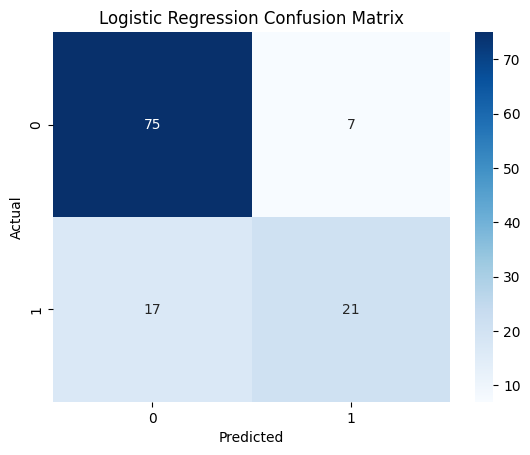

In [88]:
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [89]:
dt_cm = confusion_matrix(y_test, dt_pred, labels=['no', 'yes'])
print(dt_cm)

[[67 15]
 [14 24]]


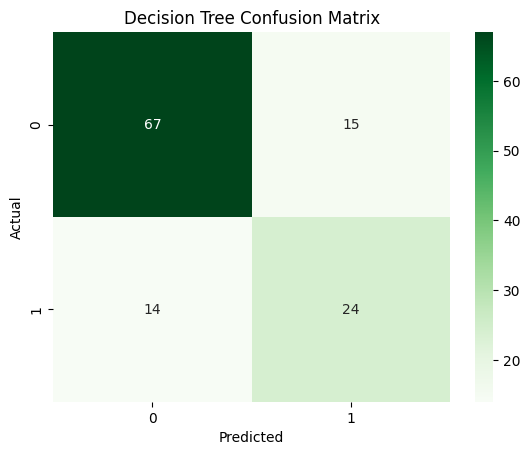

In [90]:
sns.heatmap(dt_cm, annot=True, fmt='d', cmap='Greens')
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**MODEL RECOMENDATION:**

I would recommendLogistic REgression for this business problem as it provides better performance overall. It has higher accuracy, precision and F1-score than Decision Tree. But Decision Tree has higher Recall, and since the bank wants to identify potential subscribers Decision Tree can also be used.

5.Business Interpretation and Prediction

In [91]:
dt_model = dt_pipeline.named_steps['model']
feature_names = dt_pipeline.named_steps['preprocessing'].get_feature_names_out()
importance = dt_model.feature_importances_

In [92]:
feature_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})
feature_df = feature_df.sort_values(
    by='Importance',
    ascending=False
)
feature_df.head(10)

,Feature,Importance
20,cat__personal_loan_no,0.219268
5,num__annual_income_estimate,0.157551
0,num__customer_age,0.125491
1,num__account_balance,0.120260
4,num__engagement_score,0.104649
3,num__previous_contacts,0.100555
19,cat__housing_loan_yes,0.025463
2,num__campaign_contacts,0.022510
22,cat__contact_type_cellular,0.018566
8,cat__job_management,0.013033


The feature importance analysis shows that personal_loan_no is the most influential feature.

The limitation of feature importanceis that it only shows how much a feature contributes to the model's decisions, it does not prove that the feature directly causes a customer to subscribe.

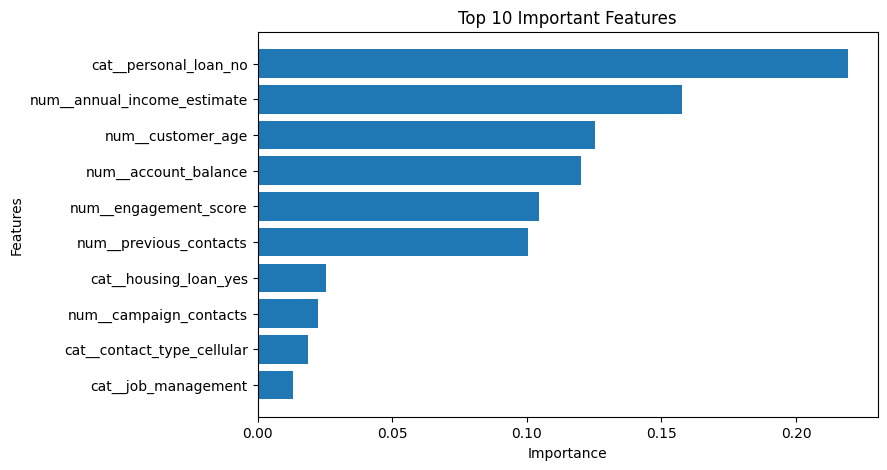

In [93]:
plt.figure(figsize=(8,5))
plt.barh(
    feature_df['Feature'].head(10),
    feature_df['Importance'].head(10)
)
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.show()

In [94]:
sample_data = X_test.head(5)
predictions = dt_pipeline.predict(sample_data)
print(predictions)
probabilities = dt_pipeline.predict_proba(sample_data)

['no' 'no' 'no' 'yes' 'no']


In [95]:
prediction_results = pd.DataFrame({
    'Actual': y_test.head(5).values,
    'Predicted': predictions,
    'Probability': probabilities[:, list(dt_pipeline.classes_).index('yes')]
})
prediction_results

,Actual,Predicted,Probability
0,yes,no,0.0
1,yes,no,0.0
2,no,no,0.0
3,no,yes,1.0
4,yes,no,0.0


**Business Conclusion:**

From the two classification models, Logistic Regression achived higher accuracy while Decision tree achived higher recall. It also identified more actual subscribers. So from a business perspective it is more suitable.
